# 07 - Error analysis

**Goal of this notebook.** The score of a model says *how often* it fails, not *why*. Here I look at the mistakes of the best model: which kinds of
questions it gets wrong, which part of the query is wrong, and what the data itself contributes to the errors.

**Discipline.** The analysis is done on the **dev set**, not on the test set (which was used once in notebook 06 for the final numbers): looking at the
test errors in order to improve the model would turn the test set into a second dev set.

Files written by this notebook:

| File | Role |
|---|---|
| `src/t2s/eval/errors.py` | the classification of the mistakes |

Tools from earlier notebooks that are used here:

| Tool | What it does | Where it is explained |
|---|---|---|
| `load_checkpoint`, `decode_examples`, `score`, `Prediction` | load a model, generate, and judge the outputs | notebook 03 |
| `target_tokens`, `build_vocab` | the output tokens; the plain vocabulary | notebook 02 |
| `SqliteExecutor`, `Query` | the database; a query | notebook 01 |

## Setup



In [1]:
import json, os, sys
from pathlib import Path

NOTEBOOK_NUMBER = 7

try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False

if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")
    PROJECT = Path("/content/drive/MyDrive/text2sql")
    CODE = "/content/code"                                      # where the notebooks write their code
    DATA_ROOT = "/content/data"                                 # the dataset (downloaded in each session)
    CKPT_DIR = "/content/drive/MyDrive/text2sql_checkpoints"    # the saved models
else:
    PROJECT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    CODE, DATA_ROOT, CKPT_DIR = str(PROJECT / "code"), str(PROJECT / "data"), str(PROJECT / "checkpoints")
os.chdir(PROJECT)   # the results are saved in the folder "results" of the project
os.makedirs(CKPT_DIR, exist_ok=True)


def rebuild_code(before):
    """Write again the code files of the notebooks 01 ... before-1 (their writefile cells)."""
    for path in sorted((PROJECT / "notebooks").glob("[0-9][0-9]_*.ipynb")):
        if int(path.name[:2]) >= before:
            continue
        for cell in json.loads(path.read_text())["cells"]:
            source = "".join(cell["source"])
            if cell["cell_type"] != "code" or not source.startswith("%%writefile"):
                continue
            first_line, _, body = source.partition("\n")
            words = first_line.split()
            target = Path(words[-1].replace("{CODE}", CODE))
            target.parent.mkdir(parents=True, exist_ok=True)
            with open(target, "a" if words[1] == "-a" else "w") as f:
                f.write(body if body.endswith("\n") else body + "\n")


for folder in ["src/t2s/data", "src/t2s/models", "src/t2s/decoding", "src/t2s/eval", "scripts", "configs"]:
    os.makedirs(f"{CODE}/{folder}", exist_ok=True)
rebuild_code(NOTEBOOK_NUMBER)
for package in ["src/t2s", "src/t2s/data", "src/t2s/models", "src/t2s/decoding", "src/t2s/eval"]:
    Path(f"{CODE}/{package}/__init__.py").touch()
sys.path.insert(0, f"{CODE}/src")

Mounted at /content/drive


In [2]:
import json
from collections import Counter
from pathlib import Path
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from t2s.data.download import download_wikisql
from t2s.data.wikisql import load_split, db_path
from t2s.data.dataset import build_vocab
from t2s.data.format import target_tokens
from t2s.eval.executor import SqliteExecutor
from t2s.eval.metrics import score
from t2s.evaluate import decode_examples
from t2s.train import load_checkpoint

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

data_dir = download_wikisql(DATA_ROOT)
splits = {name: load_split(data_dir, name) for name in ["train", "dev"]}
dev = splits["dev"]
dev_executor = SqliteExecutor(db_path(data_dir, "dev"))
Path("results/phase7_errors").mkdir(parents=True, exist_ok=True)

device: cpu


## 1. Naming the mistakes

An output is compared with the gold query part by part. An output can have several mistakes at once, and each one is named. The conditions of the output
are matched with the gold conditions **on the same column**: a matched condition can have a wrong operator or a wrong value; the conditions that cannot be
matched are paired with each other (the model chose another column) and the rest is missing or extra.

**The description** lists the eight types of mistake and the way conditions are matched.

In [3]:
%%writefile {CODE}/src/t2s/eval/errors.py
"""Classifying the mistakes of a model.

An output is compared with the gold query part by part. An output can have several mistakes
at once; each one is named:

    invalid output          the output cannot be read as a query (broken format, unknown column)
    wrong selected column   another column is selected
    wrong aggregator        another aggregator (or none) is used
    wrong condition column  a condition is on another column than the gold condition
    missing condition       a gold condition is not in the output
    extra condition         the output has a condition that is not in the gold query
    wrong operator          a condition on the right column has another operator
    wrong value             a condition on the right column has another value

A condition of the output is matched to the gold condition on the same column. The conditions
that cannot be matched are first paired with each other (the model chose another column: wrong
condition column); those left over are missing or extra.
"""

from t2s.eval.metrics import Prediction
from t2s.query import Condition, Query

ERROR_TYPES = (
    "invalid output",
    "wrong selected column",
    "wrong aggregator",
    "wrong condition column",
    "missing condition",
    "extra condition",
    "wrong operator",
    "wrong value",
)




Writing /content/code/src/t2s/eval/errors.py


**`_value`** gives the value of a condition as lowercase text with single spaces, to compare values.

In [4]:
%%writefile -a {CODE}/src/t2s/eval/errors.py
def _value(condition: Condition) -> str:
    return " ".join(str(condition.value).lower().split())




Appending to /content/code/src/t2s/eval/errors.py


**`classify`** returns the list of the mistakes of a predicted query:

1. no query (`None`): `invalid output`;
2. the selected column and the aggregator are compared directly;
3. for each gold condition, the first predicted condition on the **same column** is taken; if there is one, its operator and its value are compared; if
   there is none, the gold condition is *unmatched*;
4. unmatched gold conditions and unmatched predicted conditions are paired (`wrong condition column`); what is left is `missing condition` or `extra condition`.

In [5]:
%%writefile -a {CODE}/src/t2s/eval/errors.py
def classify(predicted: Query | None, gold: Query) -> list[str]:
    """The mistakes of a predicted query (an empty list if it is the gold query)."""
    if predicted is None:
        return ["invalid output"]

    errors: set[str] = set()
    if predicted.select != gold.select:
        errors.add("wrong selected column")
    if predicted.agg != gold.agg:
        errors.add("wrong aggregator")

    unmatched_predicted = list(predicted.conds)
    unmatched_gold = []
    for condition in gold.conds:
        match = next((p for p in unmatched_predicted if p.column == condition.column), None)
        if match is None:
            unmatched_gold.append(condition)
            continue
        unmatched_predicted.remove(match)
        if match.op != condition.op:
            errors.add("wrong operator")
        if _value(match) != _value(condition):
            errors.add("wrong value")

    paired = min(len(unmatched_gold), len(unmatched_predicted))
    if paired:
        errors.add("wrong condition column")
    if len(unmatched_gold) > paired:
        errors.add("missing condition")
    if len(unmatched_predicted) > paired:
        errors.add("extra condition")
    return [e for e in ERROR_TYPES if e in errors]




Appending to /content/code/src/t2s/eval/errors.py


**`classify_prediction`** is the same for a `Prediction` of notebook 03.

In [6]:
%%writefile -a {CODE}/src/t2s/eval/errors.py
def classify_prediction(prediction: Prediction, gold: Query) -> list[str]:
    """Like `classify`, for a `Prediction` of `metrics.score`."""
    return classify(prediction.query, gold)




Appending to /content/code/src/t2s/eval/errors.py


**`main_error`** gives the first mistake of the list, in the order of `ERROR_TYPES` (the most serious first), when only one name per output is wanted.

In [7]:
%%writefile -a {CODE}/src/t2s/eval/errors.py
def main_error(errors: list[str]) -> str:
    """The first mistake of the list, in the order of ERROR_TYPES (the most serious first)."""
    return errors[0] if errors else "none"


Appending to /content/code/src/t2s/eval/errors.py


In [8]:
from t2s.query import Query, Condition
from t2s.eval.errors import classify

gold = Query(select=0, agg=3, conds=(Condition(1, 0, "Tunisia"), Condition(2, 1, 5)))
examples = {
    "the gold query": gold,
    "another aggregator": Query(0, 0, gold.conds),
    "wrong value": Query(0, 3, (Condition(1, 0, "France"), Condition(2, 1, 5))),
    "second condition on another column": Query(0, 3, (Condition(1, 0, "Tunisia"), Condition(0, 1, 5))),
    "one condition missing": Query(0, 3, (Condition(1, 0, "Tunisia"),)),
    "no valid query": None,
}
for label, predicted in examples.items():
    print(f"{label:38s} -> {classify(predicted, gold)}")

the gold query                         -> []
another aggregator                     -> ['wrong aggregator']
wrong value                            -> ['wrong value']
second condition on another column     -> ['wrong condition column']
one condition missing                  -> ['missing condition']
no valid query                         -> ['invalid output']


**What I observe.** Each mistake gets its name, and an output with several mistakes gets several names. A query with a different order of the conditions or
different capital letters has no mistake.

## 2. The best model and its mistakes

I take the best architecture on dev (the same rule as in notebook 06), decode the whole dev set with it, and classify every output.

In [9]:
dev_scores = {}
for name in ["m2", "m3", "m2_bpe"]:
    path = Path(f"results/{name}/metrics.json")
    if path.exists():
        dev_scores[name] = json.loads(path.read_text())["dev"]["exact_match"]
assert dev_scores, "No results found: run the notebooks 03, 04 and 05 first (they train the models)."
BEST = max(dev_scores, key=dev_scores.get)
print("best architecture on dev:", BEST, {k: round(v, 4) for k, v in dev_scores.items()})

model, codec, cfg = load_checkpoint(Path(CKPT_DIR) / BEST / "best.pt", device)
outputs = decode_examples(model, dev, codec, device, cfg["data"]["max_src_len"], cfg["data"]["max_tgt_len"])
metrics, predictions = score(dev, outputs, dev_executor)
print({k: round(v, 4) for k, v in metrics.items() if isinstance(v, float)})

best architecture on dev: m2_bpe {'m2': 0.4022, 'm3': 0.4934, 'm2_bpe': 0.5485}
{'exact_match': 0.5485, 'execution_accuracy': 0.6114, 'execution_accuracy_gold_not_empty': 0.6037, 'valid_format': 0.8613, 'executable': 0.8544}


In [10]:
from t2s.eval.errors import ERROR_TYPES, classify_prediction, main_error

errors = [classify_prediction(p, ex.query) for p, ex in zip(predictions, dev)]
wrong = [i for i, e in enumerate(errors) if e]

exact = sum(p.exact for p in predictions)
equivalent = sum(1 for p in predictions if p.correct and not p.exact)
print(f"exact match               : {exact:5d} ({exact / len(dev):.1%})")
print(f"different query, same answer: {equivalent:5d} ({equivalent / len(dev):.1%})")
print(f"not exact (all mistakes)  : {len(wrong):5d} ({len(wrong) / len(dev):.1%})")

counts = Counter(e for errs in errors for e in errs)
main = Counter(main_error(errs) for errs in errors if errs)
table = pd.DataFrame({"queries with this mistake": [counts[t] for t in ERROR_TYPES],
                      "share of the failures": [counts[t] / len(wrong) for t in ERROR_TYPES],
                      "as main mistake": [main[t] for t in ERROR_TYPES]}, index=ERROR_TYPES)
table["share of the failures"] = table["share of the failures"].map("{:.1%}".format)
table.to_csv("results/phase7_errors/error_types.csv")
table

exact match               :  4619 (54.9%)
different query, same answer:   530 (6.3%)
not exact (all mistakes)  :  3802 (45.1%)


,queries with this mistake,share of the failures,as main mistake
invalid output,1168,30.7%,1168
wrong selected column,392,10.3%,392
wrong aggregator,757,19.9%,702
wrong condition column,1139,30.0%,895
missing condition,266,7.0%,164
extra condition,179,4.7%,103
wrong operator,129,3.4%,38
wrong value,713,18.8%,340


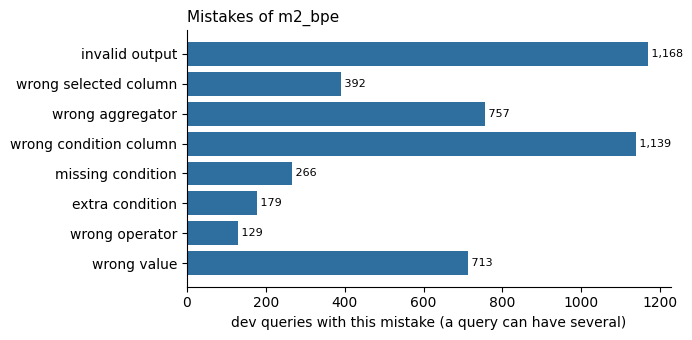

In [11]:
fig, ax = plt.subplots(figsize=(7, 3.5))
values = [counts[t] for t in ERROR_TYPES][::-1]
ax.barh(ERROR_TYPES[::-1], values, color="#2f6f9f")
for y, v in enumerate(values):
    ax.text(v, y, f" {v:,}", va="center", fontsize=8)
ax.set_xlabel("dev queries with this mistake (a query can have several)")
ax.set_title(f"Mistakes of {BEST}", loc="left", fontsize=11)
for spine in ("top", "right"):
    ax.spines[spine].set_visible(False)
plt.tight_layout()
plt.savefig("results/phase7_errors/error_types.png", dpi=150)
plt.show()

**What I observe.** *The chart shows the same picture as the table. The two longest bars are invalid output (1,168) and wrong condition column (1,139).
Wrong aggregator (757) and wrong value (713) come next.


Wrong selected column (392) is clearly shorter than the first four.
Missing condition (266), extra condition (179) and wrong operator (129) are the shortest bars. The model almost always builds a query of the right shape.

one query can appear in several bars, so the bars add up to more than the number of failures.

## 3. Where does the model fail?

The same predictions, grouped by properties of the question and of the gold query. Each group shows its size, so that a score on a very small group is not
taken too seriously.

In [12]:
from t2s.query import AGG_OPS

train_values = {" ".join(str(c.value).lower().split()) for ex in splits["train"] for c in ex.query.conds}
plain_vocab = build_vocab(splits["train"], min_freq=2)

# Tables whose numeric columns contain some text (notebook 01).
dirty = {}
with open(data_dir / "dev.tables.jsonl", encoding="utf-8") as f:
    for line in f:
        t = json.loads(line)
        dirty[t["id"]] = {i for i, kind in enumerate(t["types"])
                          if kind == "real" and not all(isinstance(row[i], (int, float)) for row in t["rows"])}

def length_group(ex):
    n = len(ex.question.split())
    return "up to 8 words" if n <= 8 else "9 to 12 words" if n <= 12 else "13 to 16 words" if n <= 16 else "more than 16 words"

features = pd.DataFrame({
    "aggregator": [AGG_OPS[ex.query.agg] or "none" for ex in dev],
    "number of conditions": [len(ex.query.conds) for ex in dev],
    "question length": [length_group(ex) for ex in dev],
    "comparison (> or <) in the query": ["yes" if any(c.op in (1, 2) for c in ex.query.conds) else "no" for ex in dev],
    "a word that is not in the vocabulary": ["yes" if any(t not in plain_vocab.stoi for t in target_tokens(ex.query, ex.header)) else "no" for ex in dev],
    "a value never seen as a value in training": ["yes" if any(" ".join(str(c.value).lower().split()) not in train_values for c in ex.query.conds) else "no" for ex in dev],
    "a numeric column that contains text": ["yes" if ({ex.query.select} | {c.column for c in ex.query.conds}) & dirty.get(ex.table_id, set()) else "no" for ex in dev],
})
features["exact"] = [p.exact for p in predictions]
features["correct"] = [p.correct for p in predictions]

def breakdown(column):
    group = features.groupby(column).agg(queries=("exact", "size"), exact_match=("exact", "mean"), execution_accuracy=("correct", "mean"))
    return group.round(3)

pieces = []
for column in ["aggregator", "number of conditions", "question length", "comparison (> or <) in the query",
               "a word that is not in the vocabulary", "a value never seen as a value in training", "a numeric column that contains text"]:
    part = breakdown(column).reset_index().rename(columns={column: "group"})
    part.insert(0, "property", column)
    pieces.append(part)
by_property = pd.concat(pieces, ignore_index=True)
by_property.to_csv("results/phase7_errors/by_property.csv", index=False)
by_property

,property,group,queries,exact_match,execution_accuracy
0,aggregator,AVG,329,0.432,0.672
1,aggregator,COUNT,779,0.376,0.487
2,aggregator,MAX,507,0.464,0.645
3,aggregator,MIN,468,0.494,0.679
4,aggregator,SUM,321,0.383,0.545
5,aggregator,none,6017,0.597,0.620
6,number of conditions,0,64,0.672,0.688
7,number of conditions,1,5755,0.606,0.647
8,number of conditions,2,2082,0.444,0.544
9,number of conditions,3,454,0.330,0.498


**What I observe.** More conditions make the task harder. Exact match drops from 60.6% (1 condition, 5,755 queries) to 44.4% (2), 33.0% (3) and 16.7% (4, only 66 queries). Every extra condition is another column and value that must be right.

Longer questions are harder. Exact match is 62.0% for questions of up to 8 words and 39.7% for questions of more than 16 words.

Unknown words and unseen values cost accuracy, but BPE copes. With an unknown word, exact match is 45.6% against 60.5% without. With a value never seen in training (55% of the dev queries), it is 48.8% against 62.2%.

COUNT and SUM are the hardest aggregators (37.6% and 38.3% exact match, against 59.7% for no aggregator). COUNT also has the lowest execution accuracy (48.7%).

Execution accuracy is much higher than exact match for AVG, MIN, MAX and SUM (for example, 67.2% against 43.2% for AVG). The model often writes a different aggregator but gets the same answer, for example when only one row matches.

This shows that exact match underestimates the model on these queries.
The same pattern appears for comparisons (> or <) and for numeric columns with text. Exact match is lower by about 11 points and 9 points, but execution accuracy is the same as for the other queries (61.3% against 61.1%, and 62.0% against 60.8%). So these queries are not harder to answer, but they are harder to write exactly as the gold query does.

## 4. Do the improvements help the same questions?

The same breakdown for several models, to see where attention and the copy mechanism help most.

In [13]:
models = {}
for name in ["m1b", "m2", "m3"]:
    path = Path(CKPT_DIR) / name / "best.pt"
    if path.exists():
        m, c, conf = load_checkpoint(path, device)
        out = decode_examples(m, dev, c, device, conf["data"]["max_src_len"], conf["data"]["max_tgt_len"])
        models[name] = [p.exact for p in score(dev, out, dev_executor)[1]]

rows = []
for column in ["number of conditions", "question length", "a word that is not in the vocabulary"]:
    for group in sorted(features[column].unique(), key=str):
        mask = (features[column] == group).to_numpy()
        row = {"property": column, "group": group, "queries": int(mask.sum())}
        for name, flags in models.items():
            row[name] = round(float(np.mean(np.array(flags)[mask])), 3)
        rows.append(row)
by_model = pd.DataFrame(rows)
by_model.to_csv("results/phase7_errors/by_model.csv", index=False)
by_model

,property,group,queries,m1b,m2,m3
0,number of conditions,0,64,0.469,0.672,0.594
1,number of conditions,1,5755,0.214,0.440,0.578
2,number of conditions,2,2082,0.056,0.330,0.355
3,number of conditions,3,454,0.011,0.258,0.115
4,number of conditions,4,66,0.000,0.121,0.015
5,question length,13 to 16 words,1859,0.108,0.372,0.449
6,question length,9 to 12 words,3052,0.179,0.409,0.531
7,question length,more than 16 words,1210,0.039,0.287,0.234
8,question length,up to 8 words,2300,0.257,0.479,0.616
9,a word that is not in the vocabulary,no,5221,0.265,0.649,0.546


## 5. Looking at the failures

Numbers hide the details. I read 100 failures, chosen at random (a fixed seed, so the list is always the same), with their mistakes.

In [14]:
rng = np.random.default_rng(0)
chosen = sorted(rng.choice(wrong, size=min(100, len(wrong)), replace=False))
rows = []
for i in chosen:
    ex, p = dev[i], predictions[i]
    rows.append({"question": ex.question.strip(), "gold": ex.query.to_sql(ex.header),
                 "predicted": p.query.to_sql(ex.header) if p.query else "(invalid) " + " ".join(p.tokens),
                 "mistakes": ", ".join(errors[i]), "same answer": p.correct})
failures = pd.DataFrame(rows)
failures.to_csv("results/phase7_errors/failures_100.csv", index=False)
pd.set_option("display.max_colwidth", 110)
pd.set_option("display.width", 250)
failures.head(25)

,question,gold,predicted,mistakes,same answer
0,"What is the amount of trees, that require replacement when district is leninsky?","SELECT Amount of trees, that require replacement FROM table WHERE District = 'Leninsky'",(invalid) <sel> <agg_none> trees <where> district <eq> leninsky <and> district <eq> leninsky,invalid output,False
1,Which Rd took place at the Indianapolis 500?,SELECT Rd FROM table WHERE Name = 'Indianapolis 500',SELECT Rd FROM table WHERE Winning team = 'indianapolis 500',wrong condition column,False
2,Give me the minimum number of people in 1991 with 92.5% of Slovenes in 1991.,SELECT MIN(Number of people 1991) FROM table WHERE Percent of Slovenes 1991 = '92.5%',(invalid) <sel> <agg_min> percent ( slovenian ) <where> percent of slovenes 1991 <eq> 92.5 %,invalid output,False
3,"What unit of length is being used for the route with ""replaced by us 81"" in their remarks section?",SELECT Length FROM table WHERE Remarks = 'Replaced by US 81',"SELECT Length FROM table WHERE Route Name = 'replaced by us 81""' AND Route Name = 'remarks'","wrong condition column, extra condition",False
4,What position is number 35 whose height is 6-6?,SELECT Position FROM table WHERE Height in Ft. = '6-6' AND No.(s) = '35',SELECT Position FROM table WHERE Height in Ft. = '6-6',missing condition,False
5,How many alt names does 1964-011a have?,SELECT COUNT(Alt name) FROM table WHERE ID = '1964-011A',(invalid) <sel> <agg_count> alt names <where> alt name <eq> 1964 - 011 a,invalid output,False
6,What was the smallest population figure for Mareeba?,SELECT MIN(Population (Mareeba)) FROM table,(invalid) <sel> <agg_min> population ( hererton ),invalid output,False
7,What football stadium has a school enrollment of 43579?,SELECT Football stadium FROM table WHERE Enrollment = 43579,(invalid) <sel> <agg_none> football stadium <where> school <eq> 43579,invalid output,False
8,How many games did the team play when they were 1-3?,SELECT COUNT(Score) FROM table WHERE Record = '1-3',SELECT COUNT(Team) FROM table WHERE Record = '1-3',wrong selected column,True
9,WHAT YEAR DID MIKE BRADY GET RUNNER-UP?,SELECT MIN(Year) FROM table WHERE Runner-up = 'Mike Brady',SELECT Year FROM table WHERE Runner-up = 'mike brady',wrong aggregator,True


In [16]:
failures.iloc[25:50]

,question,gold,predicted,mistakes,same answer
25,How many times did kevin love (22) have the high points?,SELECT COUNT(Date) FROM table WHERE High points = 'Kevin Love (22)',SELECT COUNT(Game) FROM table WHERE High points = 'kevin love (22)',wrong selected column,True
26,How many caps figures for the Doncaster Rovers?,SELECT COUNT(Cap(s)) FROM table WHERE Club(s) = 'Doncaster Rovers',(invalid) <sel> <agg_count> caps ( s ) <where> player <eq> doncaster rovers,invalid output,False
27,What is the nationality of the draft pick player who plays centre position and is going to Calgary Flames?,SELECT Nationality FROM table WHERE Position = 'Centre' AND NHL team = 'Calgary Flames',SELECT Nationality FROM table WHERE Position = 'centre' AND NHL team = 'going to calgary flames',wrong value,False
28,Who is the s color commentator when the pregame host is jon sciambi?,SELECT s Color commentator FROM table WHERE Pregame hosts = 'Jon Sciambi',(invalid) <sel> <agg_none> s color commentator <where> pregame host <eq> jon sciambi,invalid output,False
29,What pick number is Kevan George?,SELECT Pick # FROM table WHERE Player = 'Kevan George',SELECT Pick # FROM table WHERE MLS team = 'kevan george',wrong condition column,False
30,What is the total of lane(s) for swimmers from Sweden with a 50m split of faster than 26.25?,SELECT SUM(Lane) FROM table WHERE Nationality = 'sweden' AND Split (50m) < 26.25,SELECT SUM(Lane) FROM table WHERE Nationality = 'sweden' AND Split (50m) > '26.25' AND Name = 'swimmers',"extra condition, wrong operator",True
31,How many drops did Nicky Little have in Hong Kong?,SELECT Drop FROM table WHERE Player = 'nicky little' AND Venue = 'hong kong',SELECT Drop FROM table WHERE Player = 'nicky little' AND Player = 'hony little',wrong condition column,False
32,What was the crowd size at Victoria Park?,SELECT Crowd FROM table WHERE Venue = 'victoria park',SELECT SUM(Crowd) FROM table WHERE Venue = 'victoria park',wrong aggregator,False
33,"What is the earliest year it was located in gelredome, arnhem, and a Anthem of technoboy - next dimensiona...","SELECT MIN(Year) FROM table WHERE Location = 'gelredome, arnhem' AND Anthem = 'technoboy - next dimensiona...","SELECT MIN(Year) FROM table WHERE Location = 'gelredome, arnhem' AND Location = 'technoboy - next'",wrong condition column,True
34,Which LNER 1946 number is from 1892 and has an LNER number of 7347–7356?,SELECT LNER 1946 No. FROM table WHERE Year = '1892' AND LNER No. = '7347–7356',SELECT LNER 1946 No. FROM table WHERE LNER 1946 No. = '7347–7356',"wrong condition column, missing condition",False


In [17]:
failures.iloc[50:100]

,question,gold,predicted,mistakes,same answer
50,"what is the club that was founded before 2007, joined prsl in 2008 and the stadium is yldefonso solá moral...",SELECT Club FROM table WHERE Founded < 2007 AND Joined PRSL = 2008 AND Stadium = 'yldefonso solá morales s...,SELECT Club FROM table WHERE Founded < '2007' AND Stadium = 'prsl' AND Stadium = 'prsl' AND Stadium = 'yld...,"wrong condition column, extra condition, wrong value",False
51,when is the latest to join prsl when founded in 2007 and the stadium is roberto clemente stadium 1?,SELECT MAX(Joined PRSL) FROM table WHERE Founded = 2007 AND Stadium = 'roberto clemente stadium 1',SELECT MAX(Founded) FROM table WHERE Founded = '2007' AND Stadium = 'roberto clemente stadium 1',wrong selected column,False
52,Which Game has High assists of s. threatt (9)?,SELECT MIN(Game) FROM table WHERE High assists = 's. threatt (9)',SELECT Game FROM table WHERE High assists = 's. threatt (9)',wrong aggregator,True
53,"What is Jeremy's Guest, when First Broadcast is ""20 March 1998""?",SELECT Jeremy's guest FROM table WHERE First broadcast = '20 march 1998',(invalid) <sel> <agg_none> guest ( % ) <where> first broadcast <eq> 20 march 1998,invalid output,False
54,What is the 3rd for the 2nd Tui Dhuli?,SELECT 3 (F) FROM table WHERE 2 (VF) = 'tui dhuli',(invalid) <sel> <agg_none> 3 rd <where> 2 ( f ) <eq> tui dhuli,invalid output,False
55,What was the date when the opponent was Sheffield Scimitars and the venue was Home?,SELECT Date FROM table WHERE Opponent = 'sheffield scimitars' AND Venue = 'home',SELECT Date FROM table WHERE Man of the Match = 'sheffield scimitars' AND Venue = 'home',wrong condition column,False
56,What week did the contestant finish in the bottom 2 with a Celine Dion song?,SELECT Week FROM table WHERE Status = 'bottom 2' AND Artist = 'celine dion',SELECT Week FROM table WHERE Theme = 'bottom 2' AND Theme = 'celine dion song',wrong condition column,False
57,"What is Headquarter, when Newspaper/Magazine is Al-Ayyam?",SELECT Headquarter FROM table WHERE Newspaper/Magazine = 'al-ayyam',(invalid) <sel> <agg_none> denomination <where> newspaper / magazine <eq> al - ayyam,invalid output,False
58,What is the listed for the bridge at Daniel in Sublette county?,SELECT Listed FROM table WHERE County = 'sublette' AND Location = 'daniel',SELECT Listed FROM table WHERE County = 'sublette county' AND County = 'subl',"wrong condition column, wrong value",False
59,What is the date amer sulaiman won?,SELECT Date FROM table WHERE Winner = 'amer sulaiman',SELECT Date FROM table WHERE Event = 'amer sulaiman',wrong condition column,False


**What I observe.**
Invalid output: a column name that does not exist in the table. The model often writes only part of a name (trees, points, denomination) or a name that is slightly wrong. This happens most with names that contain punctuation, brackets or numbers, such as Cap(s), 3 (F), 2 (VF) and Jeremy's guest. The model writes them piece by piece and does not copy them from the table, so one wrong piece makes the whole name invalid. Some outputs also repeat a condition.

Wrong condition column. The question often does not name the column, for example “What pick number is Kevan George?” The model must guess that “Kevan George” is a Player, and it chose MLS team. The same happens with Opponent replaced by Man of the Match, or Winner by Event.

Wrong value. The value is often too long (going to calgary flames instead of calgary flames), or it is a word of the column name (nationality as a value). Because BPE spells values piece by piece, it can also make a spelling mistake: hony little instead of nicky little.

Wrong aggregator. Questions like “How many caps...” or “What was the crowd size...” do not say if they want a count, a sum or the plain value. The model writes MAX(Week) where the gold query has COUNT(Week). Many of these are hard even for a person.

Some “True” answers hide a mistake. In row 30 the model changes < into > and adds an extra condition, but the answer is marked correct. Probably both queries return an empty answer. This is the problem of empty gold answers that I found in notebook 01, and it is the reason I also report execution accuracy without them.

## 6. What the data contributes

Two things in the data make the metrics less clear (notebook 01): some gold queries have an **empty answer**, and one answer can come from several different
queries. I measure their effect on this model.

In [15]:
gold_empty = np.array([p.gold_empty for p in predictions])
correct = np.array([p.correct for p in predictions])
is_exact = np.array([p.exact for p in predictions])

print(f"gold queries with an empty answer: {gold_empty.mean():.1%}")
print(f"execution accuracy on all queries           : {correct.mean():.3f}")
print(f"execution accuracy without the empty answers: {correct[~gold_empty].mean():.3f}")
print(f"of the queries with an empty gold answer, the share counted as correct: {correct[gold_empty].mean():.1%} "
      f"(exact match: {is_exact[gold_empty].mean():.1%})")
print(f"different query but the same answer: {(correct & ~is_exact).sum()} queries")

print()
print("Examples of a different query with the same answer:")
shown = 0
for i, p in enumerate(predictions):
    if p.correct and not p.exact and not p.gold_empty and shown < 4:
        print("  question :", dev[i].question.strip())
        print("  gold     :", dev[i].query.to_sql(dev[i].header))
        print("  predicted:", p.query.to_sql(dev[i].header))
        print()
        shown += 1

gold queries with an empty answer: 7.8%
execution accuracy on all queries           : 0.611
execution accuracy without the empty answers: 0.604
of the queries with an empty gold answer, the share counted as correct: 70.3% (exact match: 45.7%)
different query but the same answer: 530 queries

Examples of a different query with the same answer:
  question : What official or native languages are spoken in the country whose capital city is Canberra?
  gold     : SELECT Official or native language(s) (alphabet/script) FROM table WHERE Capital ( exonym ) = 'Canberra'
  predicted: SELECT Official or native language(s) (alphabet/script) FROM table WHERE Capital ( endonym ) = 'canberra'

  question : What is the episode number that has production code 8abx15?
  gold     : SELECT MIN(No. in series) FROM table WHERE Production code = '8ABX15'
  predicted: SELECT MAX(No. in series) FROM table WHERE Production code = '8abx15'

  question : What is the pick number for Northwestern college?
  gold   

**What I observe.** Empty answers inflate the score only a little. 7.8% of the gold queries have an empty answer. Execution accuracy is 0.611 on all queries and 0.604 without them, a difference of 0.7 points. The result does not depend on this.

But an empty answer is easy to match. For queries whose gold answer is empty, 70.3% are counted as correct, while only 45.7% are an exact match. A wrong query that also returns nothing counts as correct, so for these queries execution accuracy is too generous.

530 queries (6.3%) are written differently but give the same answer. The examples show four cases:
a different column with the same content (Capital (exonym) instead of Capital (endonym))
a different aggregator that gives the same value when only one row matches (MIN instead of MAX)
the aggregator missing in the same situation (MAX(Pick #) replaced by Pick #)
a repeated condition, which does not change the answer.

For this reason I report both metrics. Exact match is strict and can punish a correct answer. Execution accuracy is fairer for the user, but it can reward a lucky wrong query. When both agree, I can trust the result most.

## 7. Summary of this notebook

**What I did:** named and counted the mistakes of the best model, grouped the results by properties of the questions, compared the models on the same
groups, read 100 failures, and measured the effect of the data (empty answers, equivalent queries).
